# fMRI オープンデータ解析講習
### 各ノートブックの説明
- **01**（このノートブック）：1 人分のデータに GLM を当てはめ、顔条件で強く反応する領域を探す
- **02**：同じデータで、脳の活動のパターンから、顔条件か図形条件かを当てる（デコーディング）
- **03**：別の公開データ（心の理論の課題）で、自閉スペクトラム症（ASD）の人と定型発達（以下、定型）の人の脳を、デコーディングで比べる
- **04**：さらに別の公開データ（ABIDE I）で、安静時の脳のつながりから、ASD の人と定型の人を見分ける。人数を集める意味と、当たったように見えてしまう落とし穴も見る
- **05**：まとめ（コードはありません）

# 1 人分のデータに GLM を当てはめる

代表的な fMRI の公開データベース（OpenNeuro）から fMRI のデータを取ってきて、脳画像を表示し、1 人分のデータに GLM（一般線形モデル）を当てはめて「どこが反応したか」のマップ（賦活マップ）を出します。

- **ゴール 1**：脳画像を表示する（3 章まで）
- **ゴール 2**：GLM を当てはめ、賦活マップを出す（7 章まで）

### このノートブックの読み方

左に縦線の付いていない文がメインの文章です。左に縦線が付いた「**くわしく**」は、時間があるときや、
あとで読むための部分で、講習の間は読み飛ばしてかまいません。コードは、1 行ずつ読めなくてかまいません。

### 今日の流れ

01 → 02 →（休憩）→ 03 → 04 → 05（まとめ）の順に進みます。時間になったら、途中でも次の
ノートブックに移ってかまいません。

### Colab での使い方

- セルを選んで **Shift + Enter** で実行します。**上から順に**実行してください。左に回る印が出ている間は、実行中です。
- 赤い文字（エラー）が出たら、上のセルを飛ばしていないかを確かめ、メニューの「ランタイム」→「すべてのセルを実行」を
  試してください。

> **くわしく**（時間があれば）
>
> - メインの文章だけを読めば、流れが分かるように書いてあります。
> - どのノートブックも、それだけで上から動きます。途中までしか進まなかったところは、あとで読み直せます。
> - 接続が切れると、取ってきたデータも消えます。そのときも「ランタイム」→「すべてのセルを実行」で、最初からやり直せます
>   （数分で戻ります）。
> - エラーの `NameError` は、たいてい上のセルを実行していないときに出ます。
> - GPU は使いません。

## 0. 準備

脳画像の解析と表示のための Python のライブラリ **Nilearn** を入れます。
「restart the kernel」という表示が出ても、そのまま次へ進んでかまいません。

0 章の 3 つのセルは、続けて実行するだけでかまいません。実行してから、1 章を読みます。

In [ ]:
%pip install -q nilearn==0.13.1

使う道具を読み込みます。

In [ ]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nilearn import datasets, image, plotting
from nilearn.glm import threshold_stats_img
from nilearn.glm.first_level import FirstLevelModel, make_first_level_design_matrix, spm_hrf
from nilearn.maskers import NiftiSpheresMasker
from nilearn.plotting import plot_design_matrix
from nilearn.reporting import get_clusters_table

Nilearn が出す注意書きのうち、今回の解析では気にしなくてよいものを表示しないようにします。

In [ ]:
import warnings

warnings.filterwarnings("ignore", message=".*Generation of a mask has been requested.*")
warnings.filterwarnings("ignore", message=".*'partition' will ignore the 'mask'.*")

> **くわしく**（時間があれば）
>
> 誰が実行しても同じ結果になるように、Nilearn のバージョンを `nilearn==0.13.1` に固定しています。Colab に最初から
> 入っている道具（pandas など）を入れ替えずに済むバージョンを選んでいます。

## 1. fMRI のデータが解析されるまで

fMRI のデータが撮られてから解析されるまでの流れを、今回使うデータ（https://openneuro.org/datasets/ds002785/ ）を例に、先に見ておきます。

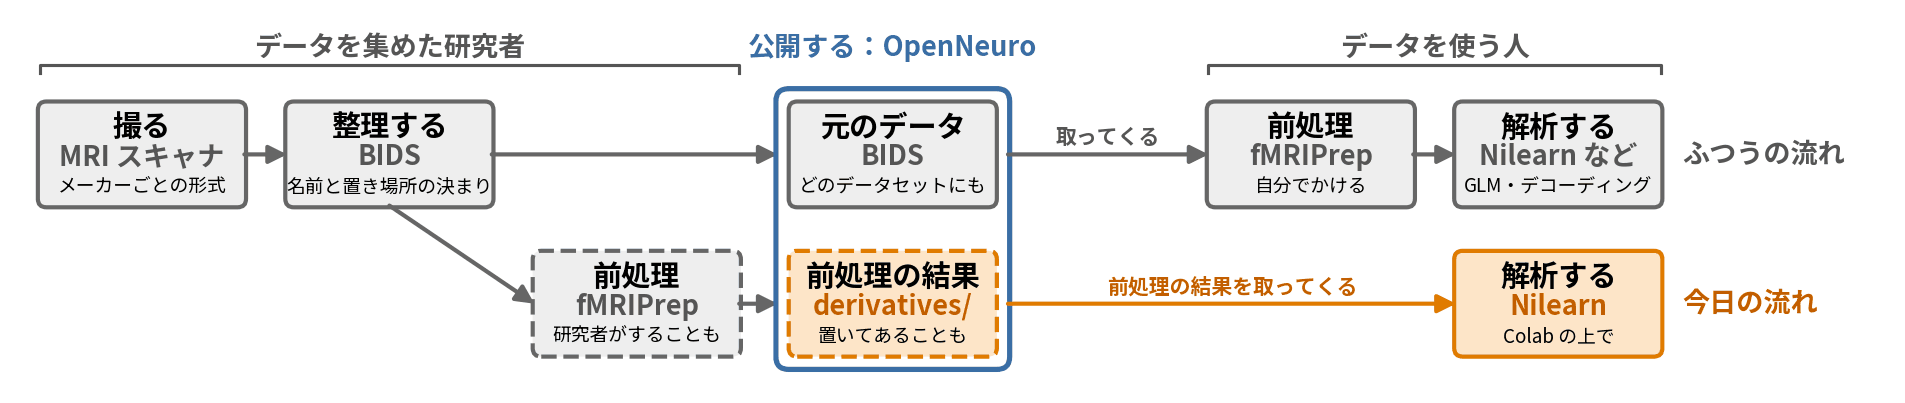

図：上の段がふつうの流れで、データを使う人が、OpenNeuro から元のデータを取ってきて、自分で前処理をかけてから解析します。
今回は下の段のように、データを集めた研究者が OpenNeuro に置いてくれた前処理の結果（点線）を取ってきて、そのまま解析します。

> **くわしく**（時間があれば）
>
> 図の上の段の左半分は、データを集めた研究者がすることです。撮った画像を BIDS にそろえて、OpenNeuro で公開します。
> データセットによっては、データを集めた研究者が前処理まで済ませ、その結果も OpenNeuro に置いています（点線）。

### 撮る：MRI スキャナ

fMRI が測っているのは、神経の活動そのものではなく、血流の変化です。神経がさかんに活動すると、少し遅れてその場所へ
流れ込む血液が増え、MRI の信号がわずかに上がります。これを **BOLD 信号** と呼びます。今回のデータは、脳全体を 2 秒に
1 枚ずつ撮っています。脳波と異なり、どこで起きたかを数 mm の細かさで、脳の深い所まで見られます。一方、時間分解能は低いです。

> **くわしく**（時間があれば）
>
> - 血液が増えると、酸素を手放したヘモグロビンの割合が下がり、そのために MRI の信号が上がります。上がり方はわずかで、
>   数 % 以下です。
> - 脳波より時間の細かさで劣るのは、血流の反応が、神経の活動から数秒遅れて、ゆっくり起こるためです（6 章の HRF）。

### 整理する：BIDS

スキャナから出てくるファイルの形式は、メーカーによって違います。そこで、脳画像の研究でよく使う **NIfTI** という形式
（`.nii.gz`）に変換し、**BIDS** という決まりに沿った名前と置き場所に並べます。決まりがあるので、初めて見るデータセット
でも、どこに何があるかがすぐに分かります。今回のデータセットの中身の一部です。

```
ds002785/
├── dataset_description.json    … データセットの名前、利用条件、著者
├── participants.tsv            … 参加者の表
├── sub-0001/
├── sub-0002/
│   ├── anat/                   … 脳の形を見る画像
│   │   └── sub-0002_T1w.nii.gz
│   ├── dwi/                    … 拡散強調画像（神経線維の走り方を見る）
│   └── func/                   … 課題などをしている間の fMRI の画像
│       ├── sub-0002_task-emomatching_acq-seq_bold.nii.gz
│       ├── sub-0002_task-emomatching_acq-seq_bold.json
│       ├── sub-0002_task-emomatching_acq-seq_events.tsv
│       └── …（ほかの課題のファイル）
├── …（sub-0216 まで）
└── derivatives/                … 前処理などの結果（下の「公開する」と「前処理」で説明します）
```

例えば `sub-0002_task-emomatching_acq-seq_bold.nii.gz` は、参加者 0002（`sub-0002`）の、表情マッチング課題
（`task-emomatching`）の、BOLD 信号の画像（`bold`）です。

> **くわしく**（時間があれば）
>
> - BIDS は Brain Imaging Data Structure の略です。上の木は、OpenNeuro のデータセットのページの「Files」でも見られます。
> - ファイル名は、`_` で区切った「キー-値」の組と、最後の種類の名前でできています。`acq-seq` は撮り方で、`seq` は脳の断面を
>   1 枚ずつ順に撮る撮り方です（このデータセットでは、3 枚ずつ同時に撮る `mb3` と区別しています）。`.nii.gz` は、NIfTI 形式を
>   圧縮したものです。
> - スキャナから出てくるファイルは、多くは **DICOM** という医療画像の形式です（今回のデータを撮った Philips 社の 3 テスラの
>   スキャナでは、PAR/REC という形式でした）。NIfTI への変換には、**dcm2niix** などの道具を使います。
> - BIDS では、課題の記録や撮り方の設定も、決まった名前のファイルで添えます。決まりに沿っているので、前処理の道具
>   （下で説明する fMRIPrep など）にも、そのまま渡せます。
> - ファイル名の最後の部分を `_events.tsv` に変えると、同じ人の同じ課題の記録が見つかります。2 章では、この決まりを使って、
>   取ってくるファイルの場所を組み立てます。

### 公開する：OpenNeuro

**OpenNeuro**（<https://openneuro.org/>）は、BIDS にそろえた脳画像のデータを公開する場所です。名前などの情報を消し、
顔の部分を削ってから公開されています。置いてあるのは、基本的には **元のデータ** ですが、今回のデータセットのように、
前処理した **結果** も `derivatives/` というフォルダに置いてあるものもあります（図の点線）。

> **くわしく**（時間があれば）
>
> - 元のデータは、BIDS に変換した直後のデータです。
> - データを上げるときに、BIDS の決まりに沿っているかが自動で確かめられます。
> - 公開の前に、名前や生年月日などの情報を消し、脳の形を見る画像（T1 強調画像。上の木の `T1w`）からは、顔（口と鼻）の部分を
>   削っています（**defacing**）。参加者の番号も付け直しています。
> - 今回のデータセットは、誰でも自由に使える条件（CC0）で公開されています。

### 取ってくる

OpenNeuro のデータは、登録しなくても取ってこられます。BIDS では、参加者の表はいつも、データセットのいちばん上にある
`participants.tsv` です。読み込んでみます。

In [ ]:
participants = pd.read_csv("https://s3.amazonaws.com/openneuro.org/ds002785/participants.tsv", sep="\t")
print("number of participants:", len(participants))
participants.head()

1 行が 1 人で、216 人分あります。

> **くわしく**（時間があれば）
>
> - ファイルは、OpenNeuro が Amazon のクラウド（AWS の S3）に置いていて、`https://s3.amazonaws.com/openneuro.org/` で始まる
>   URL で 1 つずつ取ってこられます。今回のデータは、元のデータも前処理の結果も、すべてここから取ってきます。
> - 表には、年齢（`age`）、性別（`sex`）、利き手（`handedness`）のほか、性格の質問紙の得点（`NEO_` で始まる列）なども
>   入っています。列の意味は、同じ場所にある `participants.json` に書いてあります。

### 前処理：fMRIPrep

撮ったままの画像には、頭の動きによるずれや、撮り方によるゆがみがあり、脳の形や大きさも人によって違います。これらを直す
処理を **前処理** と呼びます。**fMRIPrep** は、BIDS のデータを読み込んで、前処理を自動で行う道具です。中では、いくつもの
道具が **Nipype** という枠組みでつながっていて、それらを一式詰めた **コンテナ** の形で配られ、**Docker** などで動かします。

前処理は、ふつうはデータを使う人が自分でかけ（図の上の段）、1 人分で数時間かかることもあります。今回は、OpenNeuro に
置いてある結果を使います（図の下の段）。前処理の前と後の画像は、3 章で比べます。

> **くわしく**（時間があれば）
>
> - fMRIPrep がすること
>   - 頭の動きを推定し、画像の位置を合わせ直す
>   - 同じ人の脳の形の画像（T1 強調画像）と位置を合わせ、さらに標準脳（MNI）の形にそろえる。人どうしを同じ座標で
>     比べられるようになる
>   - 頭の動きなど、雑音のもとになる量を表に書き出す（confounds。5 章で使います）
>   - 処理がうまくいったかを目で確かめるための報告書（HTML）を作る
> - fMRIPrep の中では、FSL・ANTs・FreeSurfer・AFNI など、得意な処理の違う道具が順につながっています。これらを Python で
>   つなぐ枠組みが Nipype です。
> - 道具が多く、それぞれのバージョンをそろえて自分の PC に入れるのは大変です。そこで fMRIPrep は、必要な道具を一式詰めた
>   コンテナの形で配られています。Docker（Windows や Mac でも使えます）や、大学や研究所の共用の計算機でよく使う
>   **Apptainer**（以前の名前は Singularity）で動かします。同じコンテナを使えば、誰が動かしても同じバージョンの道具で処理されます
>   （このノートブックで `nilearn==0.13.1` とバージョンを固定したのと同じ考え方です）。
> - 今回のデータセットでは、データを集めた研究者が fMRIPrep 1.4.1 を Docker で動かして前処理し、その結果を同じ
>   データセットの `derivatives/fmriprep/` に置いています。
> - 元のデータだけが公開されているデータセットに、あとから fMRIPrep をかけた結果をまとめて公開する取り組み
>   （OpenNeuro Derivatives）もあります。

## 2. 課題とデータ

使うのは、アムステルダム大学が公開しているデータセット **AOMIC PIOP1**（OpenNeuro の番号 ds002785。1 章で中身を見たもの）
です。大学生 216 人が、スキャナの中でいくつかの課題をしました。

- データセットのページ：https://openneuro.org/datasets/ds002785
- 論文のページ：https://www.nature.com/articles/s41597-021-00870-6

### 表情マッチング課題

この中の **表情マッチング課題** を使います。2 つの条件で、あわせて 48 試行を行います。

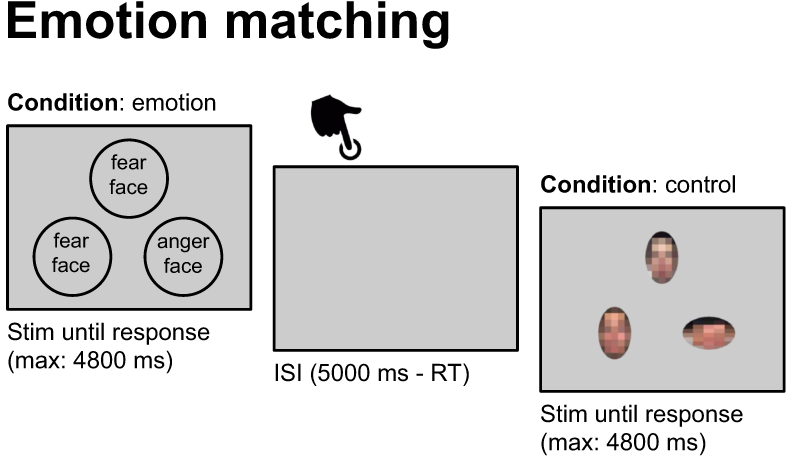

図：Snoek et al. (2021) の Fig. 2 の一部（CC BY 4.0）。左が顔条件、右が図形条件の画面です（実際には、顔条件では円の代わりに
顔のカラー写真が出ます）。

- **emotion（顔条件）**：上の顔と同じ表情（怒りか恐れ）の顔を、下の 2 枚から選びます。
- **control（図形条件）**：上の楕円と同じ向き（縦長か横長か）の楕円を、下の 2 つから選びます。楕円は顔の写真を
  モザイク状にして作ってあり、色と大きさは顔の写真とそろえてあります。

> **くわしく**（時間があれば）
>
> - 図は、上の論文の Fig. 2 から、表情マッチング課題の部分を切り出したものです。参加者は画面を見て、ボタンで答えます。
>   顔条件では、上に 1 枚、下に 2 枚、顔の写真が出ます。図形条件では、同じ並びで楕円が 3 つ出ます。
> - 図の真ん中は、答えたあとの空白の画面です。図の中の英語：Stim until response は「答えるまで刺激を出す（長くて 4.8 秒）」、
>   ISI は次の試行までの空白の時間、RT は答えるまでの時間です。
> - 顔条件の 3 枚のうち、ちょうど 2 枚が同じ表情です。1 試行の中の 3 枚は、性別と人種のまとまりがそろえてあります。
> - 答え方：左手か右手の人差し指でボタンを押して答えます。答えると画面が消えて空白になり（答えなくても 4.8 秒で消えます）、
>   次の試行は、前の試行が始まってから 5 秒後に始まります。

### 1 回の撮像の流れ

1 回の撮像（**run**）は 4 分 30 秒です。図形条件 6 試行（30 秒）と顔条件 6 試行（30 秒）を、図形条件から始めて交互に 4 回ずつ
行います。同じ条件が続く 30 秒のまとまりを **ブロック** と呼びます。

> **くわしく**（時間があれば）
>
> 最初の 10 秒と最後の 20 秒は、課題がありません（全部で 270 秒）。ブロックの順番は全員同じで、ブロックの中の刺激の順番は
> 人によって違います。

### 予想：どこが反応するか

**考えてみましょう**：顔条件のほうが、図形条件より強く反応するのは、脳のどこでしょうか。

これまでの研究からは、次の 2 つが予想されます。今回は、顔条件のほうが強く反応する場所を脳全体から探し（7 章）、
この予想と比べます（8 章）。

- 側頭葉の下の面にある **紡錘状回** の一部（**紡錘状回顔領域**、[fusiform face area、FFA](https://en.wikipedia.org/wiki/Fusiform_face_area)）。顔を見ると、ほかの物を見るときより強く反応します
  （Kanwisher et al., 1997）。
- 情動に関わる **[扁桃体](https://ja.wikipedia.org/wiki/%E6%89%81%E6%A1%83%E4%BD%93)**。この課題のもとになった研究では、怒りや恐れの表情を合わせるときに、反応が上がりました
  （Hariri et al., 2000）。

> **くわしく**（時間があれば）
>
> 「顔条件 − 図形条件」には、顔の形、表情、判断にかかる時間（4 章で見ます）など、いくつもの違いが含まれます。

### データを取ってくる

取ってくるのは 5 つのファイルです。3 つは前処理の結果、2 つ（課題の記録と、3 章で比べる前処理の前の画像）は元のデータです。
まず、解析する参加者と、取ってくるファイルの場所を決めます。

In [ ]:
subject = "sub-0002"  # 解析する参加者。9 章で別の人に変えて試せます

base = "https://s3.amazonaws.com/openneuro.org/ds002785"  # OpenNeuro の ds002785 の置き場所
prefix = f"{subject}_task-emomatching_acq-seq"
fmriprep = f"{base}/derivatives/fmriprep/{subject}/func/{prefix}"  # 前処理の結果のフォルダ

urls = {
    "bold": f"{fmriprep}_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz",  # 脳画像（前処理の結果）
    "mask": f"{fmriprep}_space-MNI152NLin2009cAsym_desc-brain_mask.nii.gz",  # 脳の範囲（前処理の結果）
    "confounds": f"{fmriprep}_desc-confounds_regressors.tsv",  # 頭の動きなど（前処理の結果）
    "events": f"{base}/{subject}/func/{prefix}_events.tsv",  # 課題の記録（元のデータ）
    "raw_bold": f"{base}/{subject}/func/{prefix}_bold.nii.gz",  # 脳画像（元のデータ。3 章で比べる）
}

5 つのファイルを取ってきます（合わせて約 150 MB）。データは、インターネットから Colab のサーバーに直接届きます。

In [ ]:
data_dir = Path("data") / subject
data_dir.mkdir(parents=True, exist_ok=True)

paths = {}
for name, url in urls.items():
    path = data_dir / url.rsplit("/", 1)[1]
    if not path.exists():
        part = path.with_name(path.name + ".part")  # 途中で切れても壊れたファイルが残らないように
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    paths[name] = path
    print(f"{name}: {path.stat().st_size / 1e6:.2f} MB")

> **くわしく**（時間があれば）
>
> - 前処理の結果は、1 章で見たように、データを集めた研究者が fMRIPrep で前処理して、同じデータセットの
>   `derivatives/fmriprep/` に置いたものです。
> - 前処理の結果のファイル名には、BIDS のキーが 2 つ増えています。
>   `sub-0002_task-emomatching_acq-seq_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz` の
>   `space-MNI152NLin2009cAsym` は標準脳（MNI）の形にそろえたこと、`desc-preproc` は前処理済みであることを表します。

## 3. 脳画像を見る（ゴール 1）

fMRI の画像は、脳の 3 次元の画像が時間に沿って何枚も並んだ **4 次元** のデータです。
形と、1 つの箱（**ボクセル**）の大きさ、撮る間隔（**TR**）を確かめます。

In [ ]:
bold = image.load_img(paths["bold"])
zooms = [round(float(v), 2) for v in bold.header.get_zooms()]
print("shape (x, y, z, time):", bold.shape)
print("voxel size (mm):", zooms[:3])
print("TR (s):", zooms[3])

2 秒に 1 枚、135 枚（4 分 30 秒）撮っています。**ボクセル** は、画像を区切った小さな箱の 1 つ 1 つで、写真の画素
（ピクセル）の立体版です。この画像では、3 mm × 3 mm × 3.3 mm の箱が 65 × 77 × 60 個並んでいます。全部を時間で平均した画像を表示します。

In [ ]:
mean_bold = image.mean_img(bold)
plotting.plot_epi(mean_bold, title="Mean BOLD image")
plotting.show()

図の見方：左から、横から見た断面（x）、前から見た断面（y）、上から見た断面（z）です。図の左が体の左です。

> **くわしく**（時間があれば）
>
> 白い十字は、3 つの断面が交わる点です。L と R は体の左と右です。x=-1 などの数は、どこで切ったかの座標（mm）です。
> 明るさは MRI の信号の強さです。

マウスで動かして見られる表示です。脳のいろいろな場所をクリックしてみてください。

In [ ]:
plotting.view_img(mean_bold, bg_img=False, cmap="gray", symmetric_cmap=False, black_bg=True, threshold=None)

### 前処理の前と比べる

1 章で見た前処理（fMRIPrep）で、画像がどう変わったかを確かめます。同じ人の、前処理の前の画像（BIDS の元のデータ）を読み込みます。

In [ ]:
raw_bold = image.load_img(paths["raw_bold"])
print("shape (x, y, z, time):", raw_bold.shape)

上の前処理の後の画像と、ボクセルの数が違います。撮ったままの画像は、スキャナの中の頭の位置と向きのままです。
前処理の後の画像は、標準脳（MNI）の枠に合わせて置き直してあります。

2 つをそれぞれ時間で平均した画像を、同じ座標で表示します。上から見た断面を、下から上へ 4 枚並べます。赤い線は、標準脳の脳の輪郭です。

In [ ]:
mni_mask = datasets.load_mni152_brain_mask()  # 標準脳の脳の範囲（Nilearn に入っている）
cuts = [-10, 10, 30, 50]  # 上から見た断面の高さ（z、mm）。下から上へ 4 枚
display = plotting.plot_epi(image.mean_img(raw_bold), display_mode="z", cut_coords=cuts, title="before preprocessing (raw)")
display.add_contours(mni_mask, levels=[0.5], colors="tab:red")
display = plotting.plot_epi(mean_bold, display_mode="z", cut_coords=cuts, title="after fMRIPrep (MNI)")
display.add_contours(mni_mask, levels=[0.5], colors="tab:red")
plotting.show()

前処理の前は、脳の位置・向き・大きさが赤い輪郭と合っていません。前処理の後は、輪郭にほぼ重なります。
こうしてそろえておくと、7・8 章で出てくる座標（MNI 座標）を、ほかの人の結果や文献の座標と比べられます。

ここまでで脳の画像が表示できていれば、**ゴール 1** 達成です。

## 4. 課題の記録（events）を見る

いつ、どの条件の刺激を呈示したかの記録です。

In [ ]:
events = pd.read_csv(paths["events"], sep="\t")
events.head(8)

- `onset`：刺激が出た時刻（撮像を始めてからの秒）
- `duration`：刺激が画面に出ていた時間。答えると消えるので、答えるまでにかかった時間（`response_time`、反応時間）と同じです
- `trial_type`：条件（emotion か control）

条件ごとに、答えるまでにかかった時間の平均を比べてみます。

In [ ]:
events.groupby("trial_type")["response_time"].mean().round(2)

顔条件のほうが、答えるまでに時間がかかっています（既定の sub-0002 では約 1.0 秒と約 0.6 秒）。
これも「顔 − 図形」の違いに含まれます。

血流の反応はゆっくりなので（6 章）、今回は 1 試行ごとではなく、30 秒のブロックごとに比べます。そこで `duration` を、
1 試行の枠の 5 秒にそろえ、6 試行をすき間なくつなげて 30 秒のブロックとして扱います。

In [ ]:
events["duration"] = 5.0
events = events[["onset", "duration", "trial_type"]]
events.head(8)

ブロックの並びを、時間に沿って描きます。オレンジが顔条件、青が図形条件のブロックです。
細い縦線は、1 試行ごとの区切りです。

In [ ]:
fig, ax = plt.subplots(figsize=(10, 1.5))
colors = {"emotion": "tab:orange", "control": "tab:blue"}
for onset, duration, trial_type in events.itertuples(index=False):
    ax.axvspan(onset, onset + duration, color=colors[trial_type], alpha=0.5)
ax.set_xlim(0, bold.shape[-1] * 2.0)  # 135 枚 × 2 秒 ＝ 270 秒
ax.set_yticks([])
ax.set_xlabel("time (s)")
plt.show()

> **くわしく**（時間があれば）
>
> - 顔条件のほうが時間がかかったぶん、顔の写真は楕円より長く画面に出ていました。
> - ほかに、正解したか（`response_accuracy`）や、どちらの手で答えたか（`response_hand`）なども記録されています。
> - 同じ条件の試行を 30 秒続けるこの形を、**ブロックデザイン** と呼びます。5 秒ごとの試行への血流の反応は、
>   互いに重なり合うので、1 試行ずつではなく、ブロックごとの違いを見ます。

## 5. 頭の動きを確かめる

撮像中に頭が動くと、信号が大きく乱れます。fMRIPrep が推定した頭の動き（平行移動 3 つと回転 3 つ）を読み込みます。
この 6 つは、あとで GLM に「余分な説明の材料」として入れます。

In [ ]:
confounds = pd.read_csv(paths["confounds"], sep="\t")
motion = confounds[["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z"]]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
motion[["trans_x", "trans_y", "trans_z"]].plot(ax=axes[0], ylabel="translation (mm)")
np.degrees(motion[["rot_x", "rot_y", "rot_z"]]).plot(ax=axes[1], xlabel="volume", ylabel="rotation (degrees)")  # ラジアンを度に直す
plt.show()

上が平行移動（mm）、下が回転（度）で、横軸は何枚目の画像か（**volume**）です。この人は、4 分 30 秒の間に、
平行移動はいちばん大きくても 0.3 mm ほど、回転は 0.4 度ほどしか動いていません。ボクセルの大きさ（3 mm）に比べて、
とても小さい動きです。

> **くわしく**（時間があれば）
>
> - 回転は、おおよそ、x が左右、y が前後、z が上下（頭と足）を結ぶ軸のまわりの回転です（rot_z は、顔を左右に向ける動き）。
> - 回転の 0.4 度は、頭の中心から 5 cm の所では、約 0.3 mm のずれにあたります。
> - 頭の動きが大きい人は、解析から外すこともあります。

## 6. GLM の準備：HRF と設計行列

GLM では、それぞれのボクセルの信号を次のように説明します。

**信号 ＝ 顔条件で予想される反応 × 重み ＋ 図形条件で予想される反応 × 重み ＋ 頭の動きなど ＋ 雑音**

これは、統計で習う回帰分析と同じ仕組みです（信号が目的変数、予想される反応が説明変数、重みが回帰係数にあたります）。
「信号」は、1 つのボクセルの 135 枚分の値の並びです。

「予想される反応」は、刺激を出していた時間（4 章の帯）に、血流の反応の遅れ方をかけて作ります（数学では **畳み込み** と
呼びます）。まず、その遅れ方の形を描きます。

In [ ]:
t_r = 2.0  # 撮る間隔（秒）
hrf = spm_hrf(t_r, oversampling=20)  # SPM と同じ形の HRF（0.1 秒刻み）
hrf_times = np.arange(len(hrf)) * t_r / 20
plt.figure(figsize=(6, 3))
plt.plot(hrf_times, hrf)
plt.xlabel("time after a brief neural event (s)")
plt.ylabel("BOLD response")
plt.show()

神経の活動が短く 1 回あると、血流の変化による信号（BOLD 信号）は少し遅れて上がり、約 5 秒後に最大になります。
そのあと少し沈んでから、ゆっくり元に戻ります。この形を **HRF**（血流動態反応関数）と呼びます。

> **くわしく**（時間があれば）
>
> HRF は、12 秒ごろに元の高さを下回り、30 秒ほどかけて元に戻ります。ここでは、fMRI の解析でよく使われるソフト **SPM** と
> 同じ形を使います。縦軸の数の大きさに意味はなく、形だけを見ます。

これを使って、予想される反応を列として並べた表（**設計行列**）を作ります。

In [ ]:
frame_times = np.arange(bold.shape[-1]) * t_r
design = make_first_level_design_matrix(
    frame_times,
    events,
    hrf_model="spm",  # SPM と同じ形の HRF
    drift_model="cosine",  # ゆっくりした信号の変化（ドリフト）を取り除く
    high_pass=1 / 128,  # 128 秒より長い周期のゆっくりした変化を取り除く（1/128 Hz）
    add_regs=motion,  # 頭の動きの 6 列を加える
)
plot_design_matrix(design)
plt.show()

この図は、設計行列を色で表したものです。縦が時間（上が 1 枚目、下が 135 枚目）、横が列で、黄色いほど値が大きい
ことを表します（列ごとに目盛りをそろえています）。emotion の列で黄色くなっている時間が、顔条件のブロックです。

設計行列は、135 行 × 13 列の表です。1 行が 1 枚の画像（時刻）、1 列が信号を説明する材料です。

- `control`・`emotion`（2 列）：予想される反応（試行の時間に HRF をかけたもの）
- `trans_x`〜`rot_z`（6 列）：頭の動き
- `drift_1`〜`drift_4`（4 列）：ゆっくりした信号の変化
- `constant`（1 列）：いつも 1 の列。信号の平均の高さにあたります

6 章の初めの式を、記号で書くと次のようになります。

**Y ＝ Xβ ＋ ε**

**Y** は 1 つのボクセルの信号（135 個の値）、**X** はこの設計行列、**β** は 13 列それぞれの重み、**ε** は説明しきれない
残り（雑音）です。**X は全部のボクセルで同じで、Y と β はボクセルごとに違います。** 7 章では、同じ X を脳のすべての
ボクセルに当てはめて、ボクセルごとに β を求めます。

顔条件の列を、4 章のブロックの帯と重ねて描きます。

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3))
for onset in events.loc[events["trial_type"] == "emotion", "onset"]:
    ax.axvspan(onset, onset + 5, color="tab:orange", alpha=0.3)
ax.plot(frame_times, design["emotion"], color="tab:orange")
ax.set_xlabel("time (s)")
ax.set_ylabel("predicted response")
plt.show()

帯（箱の形）に HRF をかけたので、上がり始めが帯より数秒遅れ、角がなまっています。帯が終わったあとも、しばらく反応が残ります。

> **くわしく**（時間があれば）
>
> - β は、Y と Xβ の差の 2 乗の合計がいちばん小さくなるように求めます（**最小二乗法**）。回帰分析と同じ求め方です
>   （7 章では、雑音の性質も考えに入れた形で求めます）。
> - 7 章の「顔条件の重み − 図形条件の重み」（コントラスト）は、β の中の emotion の重みから control の重みを引いたものです。

## 7. GLM を当てはめて賦活マップを出す（ゴール 2）

脳のすべてのボクセルで、6 章の式を当てはめます。10 秒ほどかかります。

In [ ]:
model = FirstLevelModel(mask_img=paths["mask"], smoothing_fwhm=6, noise_model="ar1")
model.fit(bold, design_matrices=design)
print("GLM fitted")

> **くわしく**（時間があれば）
>
> - 当てはめる前に、画像を少しぼかして（**平滑化**。`smoothing_fwhm=6` で 6 mm）、雑音を減らしています。
> - `mask_img` には 2 章で取ってきた脳の範囲を渡し、脳の外のボクセルは当てはめません。
> - `noise_model="ar1"` は、隣り合う時刻の雑音が似ていることを考えに入れる設定です。

「顔条件の重み − 図形条件の重み」（**コントラスト**）を計算し、その差がどれだけ確かかを z 値の地図にします。
**z 値** は、重みの差が、そのばらつき（雑音で揺れる大きさ）の何倍かを表す数で、大きいほど、偶然では起きにくい差です。

In [ ]:
z_map = model.compute_contrast("emotion - control", output_type="z_score")

次に、z 値がいくつより大きければ「反応した」とみなすか（**閾値**）を決めます。

z 値が 3.1 を超えるのは、偶然なら 1000 回に 1 回ほどです。ところが脳には約 7 万のボクセルがあるので、1 つずつこの基準で
判定すると、偶然だけでも 70 個ほどのボクセルに色が付いてしまいます（**多重比較** の問題）。そこで、脳全体のどこか 1 か所でも
偶然に色が付く確率を 5% 以下に抑えるよう、基準を厳しくします。これを **FWE**（family-wise error）の補正と呼びます。

In [ ]:
z_fwe, fwe_threshold = threshold_stats_img(z_map, alpha=0.05, height_control="bonferroni")
print("FWE threshold (z):", round(fwe_threshold, 2))

> **くわしく**（時間があれば）
>
> - z 値は、t 検定の t 値と同じ考え方です（ここでは t 値を z 値に直しています）。
> - 偶然の 70 個は、顔の方が強い（赤の）向きだけの数です。図形の方が強い（青の）向きも合わせると、140 個ほどになります。
> - ここでは一番素直な方法（**Bonferroni 補正**：5% をボクセルの数で割る）を使います。赤と青の両方の向きを合わせて 5% に
>   するので、2.5% を約 7 万で割っています。
> - SPM の FWE はランダム場理論という別の計算方法で、これと同じか、少し緩い基準になります。

FWE の補正で残った場所を色で示します。赤は「顔の方が強い」、青は「図形の方が強い」場所です。
8 枚の図は、脳を下から上へ水平に切った断面で、z= の数はその高さ（mm）です。

In [ ]:
slices = [-45, -35, -18, -8, 1, 11, 20, 30]  # 水平の断面の高さ（mm）。9 章の図も同じ高さで描く
plotting.plot_stat_map(z_fwe, threshold=fwe_threshold, display_mode="z", cut_coords=slices, title="emotion - control (FWE 5%)")
plotting.show()

既定の sub-0002 では、左の側頭葉の下の面（z=-18 の断面）と、後頭葉（z=-8 と z=1 の断面の後ろの端）に、赤い場所が
はっきり出ています。

- **側頭葉の下の面**：紡錘状回と、そのすぐ外側（下側頭回）のあたりです。2 章で予想した **紡錘状回顔領域（FFA）** が
  報告される場所と重なり、顔を見ているときに強く反応する場所です。
- **後頭葉**：目から来た情報を最初に受け取る **視覚野** と、その少し前の、物の形に反応する場所のあたりです。楕円は顔の写真と
  色と大きさをそろえてありますが、形や細かい模様は違うので、ここにも差が出ます。

> **くわしく**（時間があれば）
>
> - 右の色の帯は z 値の目盛りで、灰色の範囲は閾値に届かず、色を付けていない値です。9 章の図も、同じ高さの断面で描いて比べます。
> - FFA は右で強く出る人が多いのですが、この人では左のほうが強く出ました。1 人分の結果には、こうした個人差があります。

2 章で予想した **扁桃体** のあたり（右）に十字を合わせて表示します（座標 (21, −6, −15) は、右の扁桃体のおおよその位置の MNI 座標です）。扁桃体の反応の強さは人によって違います。

In [ ]:
plotting.plot_stat_map(z_fwe, threshold=fwe_threshold, cut_coords=(21, -6, -15), title="near the right amygdala (FWE 5%)")
plotting.show()

マウスで動かして見られる表示です。

In [ ]:
plotting.view_img(z_map, threshold=fwe_threshold)

ここまでで赤い地図が出ていれば、**ゴール 2** 達成です。

## 8. 見つかった場所の信号を見る

7 章の地図で、反応がいちばん強かった場所の信号を見てみます。既定の sub-0002 では、いちばん強い場所は
左の側頭葉の下の面（下側頭回のあたり）で、赤い場所は、少し内側や後ろの紡錘状回のあたりまで続いています。

In [ ]:
table = get_clusters_table(z_map, stat_threshold=fwe_threshold, cluster_threshold=20)  # 反応した場所の一覧（1 行目がいちばん強い場所）
peak = [round(float(v), 1) for v in table.loc[0, ["X", "Y", "Z"]]]  # いちばん強い場所の座標
print("peak (MNI, mm):", peak)

その場所の半径 6 mm の範囲の信号に、6 章の設計行列を当てはめ直し、結果を次の 2 本の線で描きます。

- 黒：信号から、頭の動きとゆっくりした変化の分を引いたもの
- 赤：GLM の予想のうち、課題の部分（emotion と control の列 × それぞれの重み）

同じ図を 2 か所で描くので、手順を関数にまとめます。次のセルは、中身を読まずに実行するだけでかまいません。

In [ ]:
def plot_signal_and_prediction(coords, title):
    masker = NiftiSpheresMasker([coords], radius=6, standardize="zscore_sample")
    signal = masker.fit_transform(bold)[:, 0]  # その場所の信号（平均 0、標準偏差 1 にそろえる）
    weights = np.linalg.lstsq(design.to_numpy(), signal, rcond=None)[0]  # 設計行列の各列の重み
    weights = pd.Series(weights, index=design.columns)
    task = ["emotion", "control", "constant"]  # 課題の 2 列と、いつも 1 の列
    prediction = design[task] @ weights[task]  # 課題で説明できる部分
    nuisance = design.drop(columns=task) @ weights.drop(task)  # 頭の動きとゆっくりした変化の部分
    offset = prediction.mean()  # 見やすいように、2 本とも平均が 0 になるようにずらす

    fig, ax = plt.subplots(figsize=(10, 3))
    for onset in events.loc[events["trial_type"] == "emotion", "onset"]:
        ax.axvspan(onset, onset + 5, color="tab:orange", alpha=0.3)
    ax.plot(frame_times, signal - nuisance - offset, color="black", label="signal (motion and drift removed)")
    ax.plot(frame_times, prediction - offset, color="tab:red", label="GLM prediction (task part)")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("BOLD (z)")
    ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  # 凡例は図の右の外に置く
    plt.show()
    print("weight of emotion:", round(weights["emotion"], 2), " weight of control:", round(weights["control"], 2))

まず、いちばん強かった場所です。

In [ ]:
plot_signal_and_prediction(peak, f"peak of the map {peak}")

顔条件（オレンジの帯）の間に信号が上がり、上がり始めは帯より数秒遅れています。赤い予想も 6 章の HRF でこの遅れを
含んでいて、黒い信号によく合っています。GLM は、これと同じことを脳のすべてのボクセルで行っています。

ただし、この場所は地図でいちばん強かったところを選んだので、合って見えるのは当然です。これは新しい証拠ではなく、
GLM が何をしたかを確かめるための図示です。

> **くわしく**（時間があれば）
>
> - 7 章では画像を平滑化し、雑音の性質も考えて当てはめたので、7 章の重みは、ここの重みと少し違います。
> - 白い部分は、ほとんどが図形条件の時間です（課題のない時間は、最初の 10 秒と最後の 20 秒だけです）。課題のない時間が
>   短いので、重みそれぞれの大きさ（0 より上か下か）には、あまり意味がありません。見るのは 2 つの重みの差で、7 章の z 値は、
>   この差がぎざぎざ（雑音）に比べてどれだけ大きいかを表していました。

次に、2 章で予想した右の扁桃体のあたり（7 章で十字を合わせた場所）で描きます。

In [ ]:
plot_signal_and_prediction((21, -6, -15), "near the right amygdala (21, -6, -15)")

扁桃体のあたりでも、顔条件の間に信号が上がっています（縦軸の目盛りが上の図と違うことに注意）。ただし、顔と図形の
重みの差は、いちばん強かった場所の半分もなく、ぎざぎざ（雑音）に埋もれがちです。

2 章の予想と比べると、紡錘状回のあたり（予想 1）は、この人 1 人のデータでも見つかりました。
扁桃体（予想 2）は、1 人分でははっきりしませんでした。研究では、何十人分を集めて調べます。

> **くわしく**（時間があれば）
>
> - 既定の sub-0002 では、扁桃体のあたりの顔と図形の重みの差は約 0.7 で、いちばん強かった場所（約 1.7）の半分もありません。
>   そのため z 値も小さく、7 章の FWE の補正では、わずかしか残りませんでした。紡錘状回のあたりは、FWE の補正を通っています。
> - 扁桃体の反応の強さは人によって違い、1 人分のデータでははっきりしないことも多いです。何十人分を集めて調べる方法
>   （集団の解析）は、10 章で触れます。

## 9. 自分で試してみよう

まず、閾値の決め方で見え方がどれだけ変わるかを比べます。補正をせずに z > 3.1 で色を付けると、
7 章の図よりずっと広い範囲に色が付きます。

In [ ]:
plotting.plot_stat_map(z_map, threshold=3.1, display_mode="z", cut_coords=slices, title="emotion - control (uncorrected, z > 3.1)")
plotting.show()

FWE よりゆるい補正として、色が付いた場所のうち偶然のものが混じる割合を 5% に抑える方法（**FDR**）もあります。

In [ ]:
z_fdr, fdr_threshold = threshold_stats_img(z_map, alpha=0.05, height_control="fdr")
print("FDR threshold (z):", round(fdr_threshold, 2))
plotting.plot_stat_map(z_fdr, threshold=fdr_threshold, display_mode="z", cut_coords=slices, title="emotion - control (FDR 5%)")
plotting.show()

> **くわしく**（時間があれば）
>
> - 補正なしの z > 3.1 は、1 つのボクセルで見れば p < 0.001 にあたる、やや厳しめの基準です。それでも、FWE の図より
>   広い範囲に色が付きます。
> - この人のように強く反応する場所が多いと、FDR の閾値は 3.1 より低くなることもあります。

ほかにも、セルを書き換えて試せます。時間があれば試してください（持ち帰って試してもかまいません）。

> **くわしく**（時間があれば）
>
> 下のセルなどを書き換えて、結果がどう変わるかを見てみましょう。
>
> 1. コントラストを `"control - emotion"` にする（図形の方が強い場所。下のセル）
> 2. `height_control` を `"fdr"` にする、`alpha` を 0.01 にする（下のセル）
> 3. 7 章の `smoothing_fwhm` を 0 や 10 にして、7 章から実行し直す
> 4. 8 章の `table.loc[0, ...]` の 0 を 1 や 3 に変えて、ほかの場所の信号を見る（`table` には反応した場所が並んでいて、
>    `table.head(10)` で中身を見られます）
> 5. 2 章の `subject` を `"sub-0001"` や `"sub-0005"` などに変えて、メニューの「ランタイム」→「すべてのセルを実行」で別の人を
>    解析する（取り直しと当てはめ直しで数分かかるので、持ち帰って試してください）

In [ ]:
z_try = model.compute_contrast("control - emotion", output_type="z_score")
z_try_thr, try_threshold = threshold_stats_img(z_try, alpha=0.05, height_control="bonferroni")
plotting.plot_stat_map(z_try_thr, threshold=try_threshold, display_mode="z", cut_coords=slices, title="control - emotion")
plotting.show()

## 10. この先へ：本格的な解析の流れ

今回は、前処理の済んだ 1 人分のデータに GLM を当てはめました（1 章の図の下の段）。研究で加わることは、最後のまとめ（05）でも
紹介します。

> **くわしく**（時間があれば）
>
> 研究では、1 章の図の上の段のように自分で前処理をかけることが多く、さらに次のことが加わります。
>
> - **自分で撮ったデータを BIDS にそろえ、fMRIPrep を走らせる**（1 章の「整理する」と「前処理」）。fMRIPrep は Docker や
>   Apptainer のコンテナで動かします。
> - **集団の解析**：何十人分の地図を集めて、人々に共通する反応を調べる（Nilearn では `SecondLevelModel`）。
> - **データの管理と再現性**：使ったデータのバージョン（DataLad など）とソフトのバージョン（コンテナ、今回の `nilearn==0.13.1`）を記録しておく。
> - **公開する**：BIDS にそろえたデータは、OpenNeuro で公開できます（1 章の「公開する」）。
>
> 参考になる場所
>
> - Nilearn：https://nilearn.github.io/
> - fMRIPrep：https://fmriprep.org/
> - BIDS：https://bids.neuroimaging.io/
> - OpenNeuro：https://openneuro.org/ （今回のデータ：https://openneuro.org/datasets/ds002785）
> - ReproNim（再現できる解析の教材）：https://repronim.org/

## 11. 使った環境を記録する

今回の解析に使った Python と道具のバージョンを表示します。結果を人に見せたり論文に書いたりするときは、
この情報も添えます。

In [ ]:
import sys

import nilearn

print("Python:", sys.version.split()[0])
print("nilearn:", nilearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)

## データと道具、文献の出典

- データ：Snoek, L., van der Miesen, M. M., Beemsterboer, T., van der Leij, A., Eigenhuis, A., & Scholte, H. S. (2021).
  The Amsterdam Open MRI Collection, a set of multimodal MRI datasets for individual difference analyses.
  *Scientific Data*, 8, 85. https://doi.org/10.1038/s41597-021-00870-6 （OpenNeuro ds002785、CC0、
  https://openneuro.org/datasets/ds002785）
- 課題の図：上の論文の Fig. 2 の一部を切り出したもの（CC BY 4.0、https://creativecommons.org/licenses/by/4.0/）
- 課題：Hariri, A. R., Bookheimer, S. Y., & Mazziotta, J. C. (2000). Modulating emotional responses: effects of a neocortical
  network on the limbic system. *NeuroReport*, 11, 43–48. https://doi.org/10.1097/00001756-200001170-00009
- 顔の写真：Tottenham, N., et al. (2009). The NimStim set of facial expressions: judgments from untrained research participants.
  *Psychiatry Research*, 168, 242–249. https://doi.org/10.1016/j.psychres.2008.05.006
- 紡錘状回顔領域：Kanwisher, N., McDermott, J., & Chun, M. M. (1997). The fusiform face area: a module in human extrastriate
  cortex specialized for face perception. *Journal of Neuroscience*, 17, 4302–4311. https://doi.org/10.1523/JNEUROSCI.17-11-04302.1997
- データの形（BIDS）：Gorgolewski, K. J., et al. (2016). The brain imaging data structure, a format for organizing and
  describing outputs of neuroimaging experiments. *Scientific Data*, 3, 160044. https://doi.org/10.1038/sdata.2016.44
- 公開の場所：Markiewicz, C. J., et al. (2021). The OpenNeuro resource for sharing of neuroscience data. *eLife*, 10, e71774.
  https://doi.org/10.7554/eLife.71774
- 形式の変換：Li, X., Morgan, P. S., Ashburner, J., Smith, J., & Rorden, C. (2016). The first step for neuroimaging data
  analysis: DICOM to NIfTI conversion. *Journal of Neuroscience Methods*, 264, 47–56. https://doi.org/10.1016/j.jneumeth.2016.03.001
- 処理をつなぐ枠組み：Gorgolewski, K., et al. (2011). Nipype: a flexible, lightweight and extensible neuroimaging data
  processing framework in python. *Frontiers in Neuroinformatics*, 5, 13. https://doi.org/10.3389/fninf.2011.00013
- 前処理：Esteban, O., et al. (2019). fMRIPrep: a robust preprocessing pipeline for functional MRI.
  *Nature Methods*, 16, 111–116. https://doi.org/10.1038/s41592-018-0235-4
- 解析：Nilearn https://nilearn.github.io/